# シェーデッド・ライトコーンを用いた確率的エラー・キャンセレーション

*使用量の目安: Heron プロセッサで 10 分（注意: これはあくまで目安です。実際の実行時間は異なる場合があります。）*

## 学習成果

* 確率的エラー・キャンセレーション（PEC）とは何か、また、そのサンプリング・オーバーヘッド $\gamma^2$ が回路に作用するノイズの総量に対して指数関数的に増加する理由
* シェーデッド・ライトコーン（SLC）が、各ノイズ項の対象観測量への寄与をどのように上から抑え、緩和の予算を重要な箇所に割り当てられるようにするのか。さらに、純粋に幾何学的なライトコーンによって得られるバイアスなしのオーバーヘッド削減に加えて、シェーディングによって、有界な残留バイアスと引き換えにサンプリング・オーバーヘッドをさらに下げられる仕組み
* `NoiseLearnerV3` で層のノイズを学習し、`samplomatic` と `Executor` プリミティブを通じてアンチノイズを注入する方法
* PEC および PEC+SLC を TREX とポストセレクションと組み合わせて、ハードウェア上で期待値を推定する方法

## 前提知識

* [Qiskit パターン](/docs/guides/intro-to-patterns) のワークフロー
* 観測量の期待値を計算するための [Estimator](/docs/guides/get-started-with-estimator) プリミティブの使い方
* [Estimator プリミティブでのエラー緩和オプションの組み合わせ](/docs/tutorials/combine-error-mitigation-techniques) で扱っている、パウリ・ツワーリングや TREX などのエラー緩和手法

## 背景

このチュートリアルでは、シェーデッド・ライトコーン（SLC）アドオンを使ってエラーを緩和する方法を示します。このアドオンは [確率的エラー・キャンセレーション（PEC）の手法](/docs/guides/error-mitigation-and-suppression-techniques#probabilistic-error-cancellation-pec) を発展させたものです。PEC では、回路内の固有の層のノイズを学習し、1 量子ビット・ゲートの適用と後処理の手法によってそのノイズを打ち消します。他の手法と比べて、PEC は緩和した結果のバイアスに対してより堅牢な上限を与えますが、QPU 時間の観点でオーバーヘッドが大きくなりがちです。PEC では、ノイズによる期待値の減衰を補償するために、平均結果を係数 $\gamma = \exp(\sum_{l,\sigma} 2\lambda_{l,\sigma})$ でリスケーリングします。ここで $\lambda_{l,\sigma}$ は、回路の層 $l$ におけるエラー・パウリ $\sigma$ の学習済みノイズ・レートです。このリスケーリングにより分散は $\gamma^2$ 倍になり、その結果 QPU 上で必要な回路の実行回数も $\gamma^2$ 倍になります。これをサンプリング・コストまたはサンプリング・オーバーヘッドと呼びます。$\gamma$ は指数関数的に増加するため、PEC は浅い回路や量子ビット数の少ない回路に限られることがよくあります。PEC について詳しくは、[Probabilistic error cancellation with sparse Pauli-Lindblad models on noisy quantum processors](https://arxiv.org/abs/2201.09866) を参照してください。

緩和する必要のないエラーを特定できれば、このサンプリング・コストを指数関数的に削減できます。この方向への第一歩は、局所性を考慮したエラー緩和を実装することです。この方法では、高速に計算できる従来の「ライトコーン」を使って、回路全体のエラーに対する観測量の感度を上から抑えることで PEC のオーバーヘッドを削減し、一部の問題では PEC をより大きな規模でも実行可能にします。このライトコーンの外側にあるエラーは測定結果に影響を与えないため、エラー・キャンセレーションの手順から除外できます。この除外によって、追加のバイアスを生じさせることなく、サンプリング・オーバーヘッドが（場合によっては大幅に）削減されます。特に、深さが一定の回路で局所観測量 $O$ を測定する場合、回路の量子ビット数を増やしていくと、必要なサンプリング・オーバーヘッドはやがて頭打ちになります（[Locality and error mitigation of quantum circuits](https://arxiv.org/abs/2303.06496) の図 2b を参照してください）。

シェーデッド・ライトコーン（SLC）はさらに一歩進んで、古典シミュレーションを使い、回路全体のエラーに対する感度をより厳密に上から抑えます。これにより、QPU 時間の一部を CPU 時間と引き換えにし、バイアスの再正規化に必要なサンプリング・オーバーヘッドを削減します。ハードなカットオフの代わりに、回路内の潜在的な各エラーに段階的な「シェード（濃淡）」が割り当てられます。シェードは、そのエラーに対する観測量の期待値の感受性の上限を表します（以下で紹介する逆伝播による上限では、この感受性は回路の初期状態にも依存します。典型的なワークフローでも、このチュートリアルでも、初期状態は全ゼロ状態です）。この精緻な特性評価により、分散を抑えつつ、より効率的で的を絞った PEC の適用が可能になると同時に、観測量の推定におけるバイアスを制御しながら調整できるようになります。詳しくは、[Lightcone shading for classically accelerated quantum error mitigation](https://arxiv.org/abs/2409.04401) を参照してください。

SLC アドオンのワークフローでは、[`samplomatic`](/docs/addons/samplomatic/index) ライブラリーと、`qiskit-ibm-runtime` v0.47.0 で Qiskit Runtime に追加された `QuantumProgram` クラスおよび `Executor` クラスを活用します。これにより、使いやすさを保ちながら、エラー抑制とエラー緩和の実行設定をよりモジュール的に制御できます。詳しくは、[ダイレクテッド実行モデル](/docs/guides/directed-execution-model) のガイドを参照してください。

### SLC によるエラー緩和ワークフローの概要

QPU のノイズのモデル化には、デバイスの各量子ビットと各エッジ上で局所的に生成される、1 量子ビットおよび 2 量子ビットのパウリ・エラー・レートを持つスパース・パウリ・リンドブラッド・ノイズモデルを使います。この選択のもとで、このチュートリアルで示す SLC によるエラー緩和ワークフローは次のとおりです。

a. CPU — 1 量子ビットおよび 2 量子ビットのパウリ・エラーについて、エラーごとの影響の上限を求める

1. 順伝播（観測量への影響の上限）。各エラーを回路の末尾まで伝播させ、観測量との交換子を計算します。
   * 計算を扱える範囲に保つため、発展の過程で演算子の項を打ち切ります。
   * 量子速度限界に基づく観測量の緩い逆伝播によって、これらの上限をさらに厳しくします。
2. 逆伝播（初期状態への影響の上限）。各エラーを回路の先頭まで伝播させ、初期状態との交換子を計算します。

b. QPU — ノイズ・レートを学習する。`NoiseLearnerV3` を使って、パウリ・リンドブラッド・ノイズモデルのレートを推定します。

c. CPU — 緩和の優先順位を決める

1. 学習したノイズ・レートで、統合した上限を更新する。事前に計算した順方向と逆方向の上限を組み合わせ、学習したノイズ・レートで更新します。
2. 計算した上限と学習したレートを使って、緩和するノイズ成分をランク付けする。考えられる各ノイズ・エラーについて、バイアスへの推定影響と、それを補正するためのコストに基づいて優先順位を付けます。

d. QPU — アンチノイズを挿入して実行する。`Box` アノテーションを使って指定したアンチノイズ（逆ノイズ）を加えて、対象の回路を実行します。

e. CPU — 観測量を推定する。期待値を計算します。その際、非マルコフ的ノイズの影響を減らすために、測定に基づくポストセレクションを適用します。

### ノイズ学習の概要

ノイズ学習は、いくつかのエラー緩和手法に共通するステップであり、[ノイズ・ラーナー](/docs/guides/noise-learning) によって実行されます。これは [確率的エラー増幅のチュートリアル](/docs/tutorials/probabilistic-error-amplification) にも登場します。`NoiseLearnerV3` では、学習対象のノイズ層を [`CircuitInstruction`](/docs/api/qiskit/qiskit.circuit.CircuitInstruction) オブジェクトとして明示的に指定できるため、上で説明した方法で各層について目的の SLC ノイズ上限を計算できます。学習したパウリ・リンドブラッド・モデルは、PEC+SLC の優先順位付けに使う係数を提供します。ゲートをどのように層にまとめるかは、便利な関数 `generate_boxing_pass_manager` と `find_unique_box_instructions` を使って決定し、以下のステップ 2 で説明するように、SLC のユーティリティー関数 `generate_noise_model_paulis` に渡します。

| **パート 1**                                                                                                        | **パート 2**                                                                                                     | **パート 3**                                                                                                 |
| ----------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------- |
| 2 量子ビット・ゲートの層をパウリ・ツワーリングする                                                                                 | 恒等となる層のペアを繰り返してノイズを学習する                                                                | 忠実度（各ノイズチャネルのエラー）を導出する                                                           |
| ![パウリ・ツワーリング](https://quantum.cloud.ibm.com/docs/images/tutorials/pec-with-shaded-lightcones/paulitwirl.avif) | ![層の学習](https://quantum.cloud.ibm.com/docs/images/tutorials/pec-with-shaded-lightcones/learnlayer.avif) | ![曲線のフィット](https://quantum.cloud.ibm.com/docs/images/tutorials/pec-with-shaded-lightcones/curvefit.avif) |

### 後処理の概要

`samplomatic` と `Executor` のフレームワークを使って量子ハードウェアで実行した後、ビット列の測定結果を目的の観測量の値に変換します。このチュートリアルでは、ミラー化したイジング回路（以下のステップ 1 で構成）でワークフローを示します。この回路では、後半が前半を元に戻すため、測定する観測量の理想的な期待値は 1 になります。`executor_expectation_values` 関数で観測量の値を計算する際には、ノイズの影響を減らすためにいくつかの後処理の手法を適用します。これには、非マルコフ的ノイズの影響を受けたショットの除去、読み出しエラー緩和、そして PEC の実装の詳細への対応が含まれます。詳細は以下のステップ 4 で説明します。

## 要件

このチュートリアルを始める前に、次のものがインストールされていることを確認してください。

* Qiskit SDK v2.2 以降（[可視化](/docs/api/qiskit/visualization) サポート付き）
* Qiskit Runtime v0.47 以降（`pip install qiskit-ibm-runtime`）
* シェーデッド・ライトコーン Qiskit アドオン v0.1 以降（`pip install qiskit-addon-slc`）
* Qiskit アドオンユーティリティ v0.3 以降（`pip install qiskit-addon-utils`）
* Samplomatic v0.13 以降（`pip install samplomatic`）

## セットアップ

まず、このノートブックの実行に必要なパッケージと関数をインポートします。

In [1]:
from multiprocessing import set_start_method

# この値を設定すると、UNIX 系システムで itertools.starmap のデッドロックを防げる
set_start_method("spawn")

# PySCF が内部で並列化するのを防ぐために必要（SLC のみ）
%set_env OMP_NUM_THREADS=1

env: OMP_NUM_THREADS=1


In [2]:
import numpy as np
from matplotlib import pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager, PassManager

from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    QuantumProgram,
    Executor,
    NoiseLearnerV3,
)

import samplomatic
from samplomatic.utils import find_unique_box_instructions
from samplomatic.transpiler import generate_boxing_pass_manager

from qiskit_addon_utils.exp_vals.measurement_bases import (
    get_measurement_bases,
)
from qiskit_addon_utils.exp_vals.expectation_values import (
    executor_expectation_values,
)
from qiskit_addon_utils.noise_management import (
    gamma_from_noisy_boxes,
    trex_factors,
)
from qiskit_addon_utils.noise_management.post_selection import PostSelector
from qiskit_addon_utils.noise_management.post_selection.transpiler.passes import (
    AddPostSelectionMeasures,
    AddSpectatorMeasures,
)

from qiskit_addon_slc.bounds import (
    compute_backward_bounds,
    compute_forward_bounds,
    compute_local_scales,
    merge_bounds,
    tighten_with_speed_limit,
)
from qiskit_addon_slc.utils import (
    generate_noise_model_paulis,
    map_modifier_ref_to_ref,
)
from qiskit_addon_slc.visualization import draw_shaded_lightcone

## 小規模なシミュレーターでの例

他の学習ベースのエラー緩和手法と同様に、シェーデッド・ライトコーンを用いた PEC は特定の量子プロセッサーの *物理的な* ノイズを緩和するものであり、理想的なシミュレーター上では意味のある対応物がないハードウェアのサービスに依存しています。

* `NoiseLearnerV3` は、固有の 2 量子ビット層のそれぞれについて、スパース・パウリ・リンドブラッド・ノイズチャネルを実験的に特性評価します。ノイズのないシミュレーターでは、打ち消すべきノイズがありません。
* `Executor` プリミティブは、`samplomatic` が生成した、ツワーリングとアンチノイズの注入を施した回路をバックエンド上でサンプリングします。

シェーデッド・ライトコーンの上限の計算は古典的なものですが、緩和の予算とサンプリング・オーバーヘッドを決める、学習済みのハードウェアのノイズ・レートと組み合わせて初めて意味を持ちます。こうした理由から、小規模なシミュレーターでの例は省略し、PEC+SLC のワークフロー全体をハードウェア上で直接示します。Qiskit パターンの各ステップは以下で個別に説明します。

## 大規模なハードウェアでの例

IBM Quantum® のハードウェアで実行する 20 量子ビットのミラー化したイジング回路に対して、Qiskit パターンの 4 つのステップに従い、PEC+SLC のワークフロー全体を実行します。

### ステップ 1: 問題をマッピングする

このデモンストレーションの設定は次のとおりです。

1. 1 次元イジング鎖ハミルトニアンのもとでの時間発展を行います。1 次元イジング鎖は密な回路構造になるため、PEC の実装を示すのに便利です。
2. 観測量 $\langle X_6 Z_{13}\rangle$ を測定します。この観測量には $X$ 成分と $Z$ 成分が 1 つずつ含まれます。これは、SLC の上限が異なる種類のエラーをどのように異なって扱うかを強調するのに便利です。
3. 緩和した推定値の品質を判断しやすいように、この観測量の理想的な期待値がちょうど 1 になるようにしたいと考えます。回路をミラー化すると、ほぼこれが実現できます。回路の後半にあるすべてのゲートに対して前半に逆ゲートがあるため、理想的な回路は恒等演算として作用します。
4. 最後に、理想的な期待値 1 を得るには、回路が観測量の +1 固有状態から始まる（したがって、ミラー化のおかげで理想的には +1 固有状態で終わる）必要があります。観測量には $Z$ 以外の成分が含まれており、`Executor` プリミティブは回路の末尾で目的の測定基底を考慮するため、`prepare_basis` 関数を使って、対応する基底準備ゲートをミラー回路の先頭に追加します。どのゲートが必要で、どこに配置するかを特定するには `get_measurement_bases` 関数を使います。その際、正準基底の測定の準備に関するセクションで説明するように、`box` アノテーションの規約に起因する量子ビット・インデックスの細かな点にも注意します。

In [3]:
# イジング鎖の幅（このデモンストレーションの自由パラメーター）
num_qubits = 20

# 測定する観測量: 上記の「ステップ 1: 問題をマッピングする」で説明したとおり、
# X 成分（量子ビット 6）と Z 成分（量子ビット 13）を 1 つずつ含む
target_obs_sparse = [("XZ", [6, 13], 1.0)]

In [4]:
observable = SparsePauliOp.from_sparse_list(
    target_obs_sparse, num_qubits=num_qubits
)

In [5]:
# この観測量に対して、各量子ビットに必要な測定基底を決定する。
# reverser はステップ 4 の後処理で使う。
bases_virt, reverser_virt = get_measurement_bases(observable)

In [6]:
# デモンストレーション回路の自由パラメーター: トロッター・ステップ数で回路の深さが決まり、
# rx_angle は各ステップで適用する横磁場の回転角
# （pi/4 にするとダイナミクスが非クリフォードになる）
num_trotter_steps = 10
rx_angle = np.pi / 4

In [7]:
def construct_ising_circuit(
    num_qubits: int,
    num_trotter_steps: int,
    rx_angle: float,
) -> QuantumCircuit:
    circuit = QuantumCircuit(num_qubits)

    for _ in range(num_trotter_steps):
        circuit.rx(rx_angle, range(num_qubits))
        for first_qubit in (1, 2):
            for idx in range(first_qubit, num_qubits, 2):
                # Rzz(-pi/2) と等価:
                circuit.sdg([idx - 1, idx])
                circuit.cz(idx - 1, idx)

    return circuit


def prepare_basis(
    circuit: QuantumCircuit, basis: list[int]
) -> QuantumCircuit:
    # basis は 0 から 3 の整数値のリスト。各値は次のように基底測定に対応する:
    # 0 = I; 1 = Z; 2 = X; 3 = Y
    assert len(basis) == circuit.num_qubits

    out_circ = circuit.copy_empty_like()
    for qb, bas in enumerate(basis):
        if bas == 2:
            out_circ.h(qb)
        elif bas == 3:
            out_circ.rx(-np.pi / 2, qb)

    out_circ.barrier()
    out_circ.compose(circuit, inplace=True)
    return out_circ


def mirror_circuit(circuit: QuantumCircuit) -> QuantumCircuit:
    mirror_circ = circuit.copy_empty_like()
    mirror_circ.compose(circuit.inverse(), inplace=True)
    mirror_circ.barrier()
    mirror_circ.compose(circuit, inplace=True)
    mirror_circ.measure_active()
    return mirror_circ

In [8]:
# ミラー化した回路をインスタンス化し、先頭に基底準備ゲートを追加する
circuit = construct_ising_circuit(num_qubits, num_trotter_steps, rx_angle)
mirrored_circuit = mirror_circuit(circuit)
mirrored_circuit = prepare_basis(mirrored_circuit, bases_virt[0])

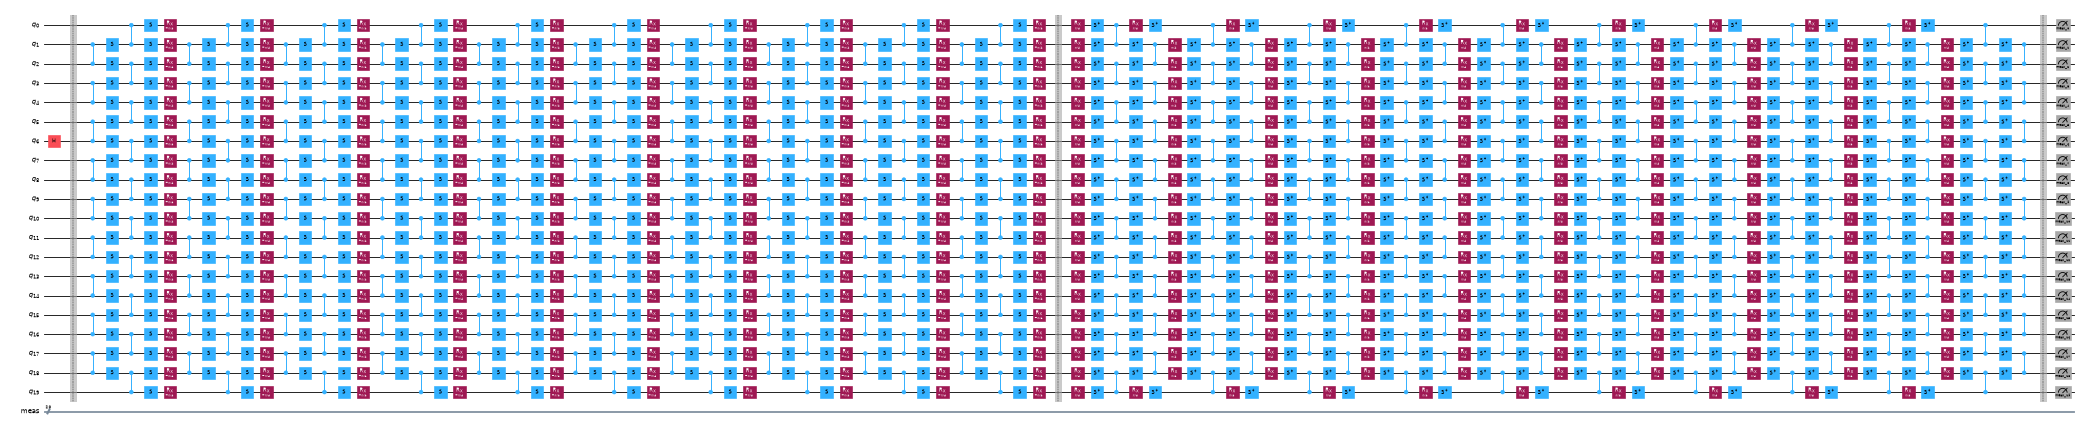

In [9]:
mirrored_circuit.draw(
    "mpl", fold=-1, scale=0.3, idle_wires=False, measure_arrows=False
)

### ステップ 2: 最適化する

実行する回路、測定する観測量、ノイズ学習のパラメーターに関する詳細を最適化します。まず、最も混雑していない Heron プロセッサーを選び、フラクショナル・ゲートを有効にしてインスタンス化します。フラクショナル・ゲートを使うと、ポストセレクションによるフィルタリングの一部で感度を高められます。

In [10]:
# 保存済みの認証情報を使って IBM Quantum Compute Service を初期化する
service = QiskitRuntimeService()

# 最も混雑していない Heron デバイスを選ぶ。このチュートリアルは Heron プロセッサーを対象としている。
# 使用量の目安と、ステップ 4 で説明する非マルコフ的ノイズのポストセレクションは、
# このプロセッサー・ファミリーに固有のものである。
backend = service.least_busy(
    operational=True,
    simulator=False,
    filters=lambda b: b.processor_type["family"] == "Heron",
)
# フラクショナル・ゲートを有効にして再取得する（least_busy はこの設定を引き継がない）
# フラクショナル・ゲートを有効にすると、非クリフォードの Rx 回転がネイティブにサポートされる。
backend = service.backend(backend.name, use_fractional_gates=True)
print(f"選択したバックエンド: {backend.name}")

選択したバックエンド: ibm_fez


まず、[QPU での実行に必要なとおり](/docs/guides/transpile#instruction-set-architecture)、回路を ISA 命令にトランスパイルします。コヒーレンス時間やゲート忠実度はデバイス内でばらつきがあり、時間とともにドリフトするため、実行に使う物理量子ビットの選択は結果の品質に大きな影響を与えます。慎重な実験では、簡単なベンチマーク実験の結果をもとに量子ビットの鎖を手動で選ぶと効果がある場合があります（たとえば、[量子ビット選択のためのリアルタイム・ベンチマーク](/docs/tutorials/real-time-benchmarking-for-qubit-selection) のチュートリアルを参照してください）。このチュートリアルでは、Qiskit のトランスパイラーに任せて、バックエンドのカップリング・マップと最新のキャリブレーション・データに基づいてレイアウトを選択します。

In [11]:
isa_pm = generate_preset_pass_manager(backend=backend, optimization_level=1)

isa_circuit = isa_pm.run(mirrored_circuit)

# トランスパイラーが選択した物理量子ビットの鎖
layout = isa_circuit.layout.final_index_layout()
print(f"選択したレイアウト: {layout}")

isa_observable = observable.apply_layout(
    layout, num_qubits=isa_circuit.num_qubits
)

選択したレイアウト: [88, 89, 78, 69, 70, 71, 58, 51, 50, 49, 48, 47, 46, 45, 37, 25, 24, 23, 22, 21]


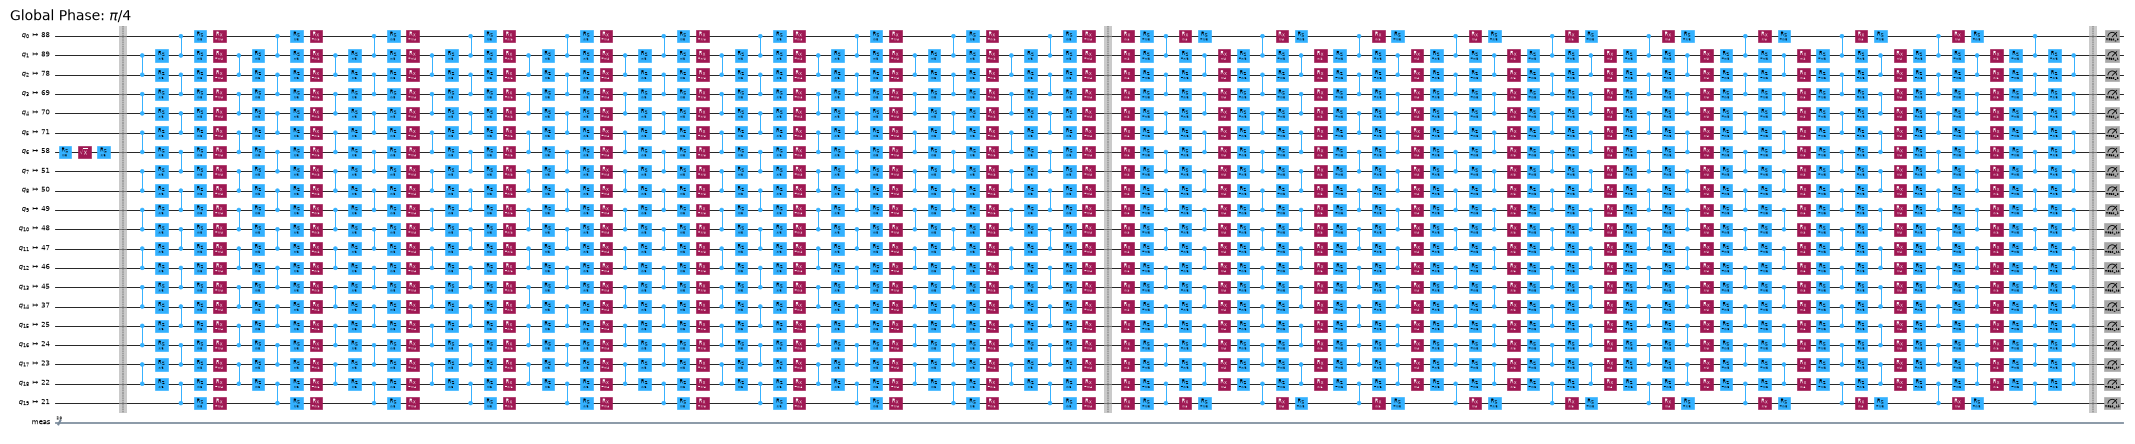

In [12]:
wire_order = layout + [
    q for q in range(isa_circuit.num_qubits) if q not in layout
]
isa_circuit.draw(
    "mpl",
    fold=-1,
    scale=0.3,
    idle_wires=False,
    wire_order=wire_order,
    measure_arrows=False,
)

### 回路をボックス化する

実装を容易にするために、`generate_boxing_pass_manager` のトランスパイル・パスを利用します。このパスは、回路の命令をアノテーション付きのボックスに配置します。これらのボックスは、PEC の場合にアンチノイズを回路のどこに注入すべきかを明確に示します。設定の詳細については、[Samplomatic のドキュメント](/docs/addons/samplomatic/) を参照してください。

なお、SLC のワークフローでは、後の工程で `inject_noise_strategy="individual_modification"` を使う必要があります。これにより、回路内の `BoxOp` 命令の `InjectNoise` アノテーションを一意に識別できるようになるためです（`InjectNoise` アノテーションのないボックスは、この方法では識別できません）。

<Admonition type="caution">
  SLC の上限の計算では現在、`InjectNoise` アノテーションが `site="after"` で配置されていることを前提としています（[qiskit-addon-slc#33](https://github.com/Qiskit/qiskit-addon-slc/issues/33) を参照してください）。最近のバージョンの `samplomatic` でこの設定のデフォルト値が変更されたため（[samplomatic#372](https://github.com/Qiskit/samplomatic/pull/372) を参照してください）、以下では `inject_noise_site="after"` を明示的に設定しています。
</Admonition>

`find_unique_box_instructions` 関数は、与えられたボックス化済みの回路を走査し、ノイズ学習とノイズ注入のために、固有の 2 量子ビット（2Q）層または測定を持つものを特定します。

In [13]:
# Twirl と InjectNoise のアノテーションを付けて回路をボックス化する
boxes_pm = generate_boxing_pass_manager(
    twirling_strategy="active",
    inject_noise_strategy="individual_modification",
    inject_noise_site="after",
    inject_noise_targets="gates",
    measure_annotations="all",
)


boxed_circuit = boxes_pm.run(isa_circuit)

# ボックス化した回路から固有の命令（層）を見つける
unique_2q_instructions = find_unique_box_instructions(
    boxed_circuit, normalize_annotations=None, undress_boxes=True
)

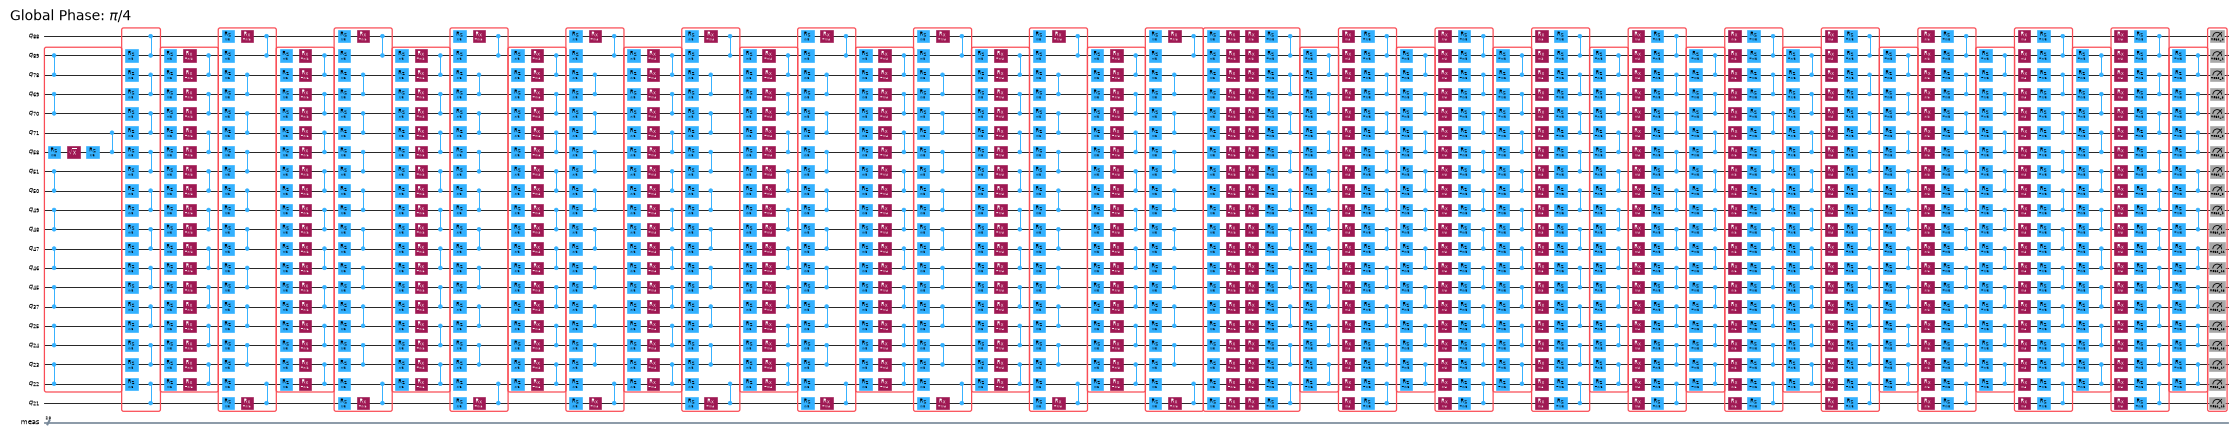

In [14]:
boxed_circuit.draw(
    "mpl",
    fold=-1,
    scale=0.3,
    idle_wires=False,
    wire_order=wire_order,
    measure_arrows=False,
)

### 正準基底の測定を準備する

量子ビットの順序を追跡することには、特に注意が必要です。回路のボックス化と固有の命令の検出において量子ビットの順序がどのように扱われるかを踏まえ、以下では、Executor に渡す際に量子ビットの順序を適切に更新する手段として `canonical_qubits` という概念を導入します。詳しくは、[量子ビットの順序の規約](/docs/addons/samplomatic/guides/samplex-io#qubit-ordering-convention) のドキュメントを参照してください。

In [15]:
# 正準量子ビットの順序を決定する
meas_box = boxed_circuit.data[-1]
canonical_qubits = [
    idx
    for idx, qubit in enumerate(boxed_circuit.qubits)
    if qubit in meas_box.qubits
]

# 正準量子ビットを物理（ISA）量子ビットに対応付ける
c_2_p = {c: p for c, p in enumerate(canonical_qubits)}
# 物理（ISA）量子ビットを仮想量子ビット（元の回路でのインデックス）に対応付ける
p_2_v = {p: v for v, p in enumerate(layout)}
# 仮想量子ビットと正準量子ビットのインデックス間の対応を計算する。
c_2_v = {c: p_2_v[p] for c, p in c_2_p.items()}

assert len(c_2_v) == num_qubits

bases_canon = [
    np.array([base_i[c_2_v[c]] for c in range(num_qubits)], dtype=np.uint8)
    for base_i in bases_virt
]

### ライトコーン・シェーディング、ノイズ学習、アンチノイズ注入のワークフロー

<Admonition type="note">
  このチュートリアルでは、緩和対象の回路をできるだけ学習済みのノイズモデルに近いタイミングで実行できるように、ノイズ学習が完了する前に SLC の上限の計算を実行します。原理的には、このワークフローはさらに並列化できます。ノイズ上限を推定している間に、並行してノイズ学習のジョブを実行できます。任意の量子回路では、ノイズ上限の計算量は弱い指数関数的な依存性でスケールすることがあるため、上限の計算を（たとえば多数の CPU コアにわたって）並列化すると、一定の計算時間の予算でより厳しい上限が得られます。さらに、QPU での実行と上限の計算自体を並列化することで、最も効率的なワークフローを実現できます。
</Admonition>

#### 学習対象のノイズモデルのパウリ項を予測する

ハードウェアでノイズ学習を実行する前に、まずノイズモデルにどのパウリ・エラー項が含まれるかを列挙します。各固有層のノイズは、アクティブな各量子ビット上の重み 1 のパウリ（$X$、$Y$、$Z$）ごとに 1 つ、接続されたアクティブな量子ビットの各ペア上の重み 2 のパウリごとに 1 つのエラー・レートを持つ、スパース・パウリ・リンドブラッド・モデルとしてモデル化することを思い出してください。`generate_noise_model_paulis` 関数は、与えられた回路のボックス化された各固有層を走査し、回路の量子ビット接続性を考慮して、まさにこのパウリ項のリストを生成します。

言い換えると、このステップでは、`NoiseLearnerV3` が後で学習したレートで埋めることになるノイズモデルの *構造* を予測します。この構造を事前に知っておくことで、ノイズ学習を実行する前に、すべての潜在的なエラーについて順方向と逆方向の上限を計算できるようになります。

In [16]:
noise_model_paulis = generate_noise_model_paulis(
    unique_2q_instructions, backend.coupling_map, boxed_circuit
)

In [17]:
noise_model_rates = {ref: None for ref in noise_model_paulis}

##### a. 順方向の上限を計算する

`compute_forward_bounds` 関数は、順伝播したエラーが目的の観測量 $A$ にどのように影響するかという観点から、各層のゲートと上で生成したパウリ項との交換関係を評価します。パウリ項と交換するゲートについては、何もしません。クリフォード・ゲートは、回路の先頭に向かって押し出されます。非クリフォード・ゲートについては、（すべての上限を統合した後で）ノイズ・キャンセレーションの優先順位付けに使うために、対象の観測量への影響を近似します。この上限は、まず L2 ノルム（すなわち、関連するパウリ項の係数の二乗和の平方根）を適用することで得られます。関係する量子ビットの項が多すぎる場合は、三角不等式を使ったより緩い上限に切り替えます。

#### 上限の計算パラメーターを設定する

次の設定で、古典的な上限の計算を制御します。

* `slc_atol`: 計算の絶対許容誤差。係数がこのしきい値を下回る演算子の項は無視できるものとして破棄されます。
* `slc_eigval_max_qubits`: より厳しい固有値ベース（L2 ノルム）の上限を評価する最大の量子ビット数。これより多くの量子ビットにまたがる演算子では、上で説明したより緩い三角不等式による上限に切り替わります。
* `slc_evolution_max_terms`: 演算子を回路に沿って伝播させる間に保持するパウリ項の最大数。最も小さい項を打ち切ることで、上限がわずかに緩くなる代わりに、計算を扱える範囲に保てます。
* `slc_num_processes`: 上限の計算を並列化する CPU プロセスの数。
* `slc_timeout`: 上限の計算の時間予算（秒）。この予算内に到達しなかった層には、自明な上限 2 が割り当てられます。

<Admonition type="note">
  このチュートリアルでは、*意図的に* タイムアウトに達するようにしています。ノートブックを素早く実行できるように `slc_timeout` をあえて小さくしており、またタイムアウトに達しても安全であることを示すためです。計算されるシェードはどの段階でも上限であるため、タイムアウトに達しても、到達しなかった層の上限が緩く（自明に）なるだけで、エラーの影響を過小評価することは決してありません。これは以下の可視化で、左端の層が自明な上限で完全に塗りつぶされる形で現れます。タイムアウト（またはプロセス数）を増やすと、上限が厳しくなり、サンプリング・オーバーヘッドをさらに削減できます。
</Admonition>

In [18]:
slc_atol = 1e-8
slc_eigval_max_qubits = 18
slc_evolution_max_terms = 1000
slc_num_processes = 8
slc_timeout = 60

In [19]:
forward_bounds = compute_forward_bounds(
    boxed_circuit,
    noise_model_paulis,
    isa_observable,
    evolution_max_terms=slc_evolution_max_terms,
    eigval_max_qubits=slc_eigval_max_qubits,
    atol=slc_atol,
    num_processes=slc_num_processes,
    timeout=slc_timeout,
)

Bounds computation timed out.


#### 目視確認のために SLC を可視化する

測定とパウリ項が局所的なエラーとどのように相互作用するかを調べることで、シェード付きの上限の振る舞いを解釈できます。これらのパターンは、このキックド・イジング・ハミルトニアンの時間発展問題に特有のものであり、論文 [Lightcone Shading for Classically Accelerated Quantum Error Mitigation](https://arxiv.org/abs/2409.04401) にも現れます。特徴的な点がいくつかあります。

* 観測量に含まれる 2 つの非恒等パウリから生じる 2 つのコーンをはっきりと区別できます。
* 量子ビット 6 の X 測定は、右端の層の X エラーと交換することが分かります。
* 量子ビット 13 の Z パウリは、右端の層の Z エラーと交換することが分かります。
* 上で指定したタイムアウトに達すると、左側の残りの層は自明な上限 2 で完全に塗りつぶされます。

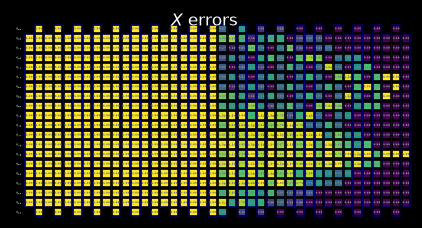

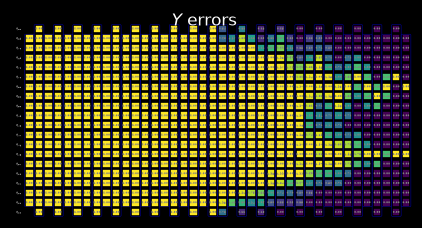

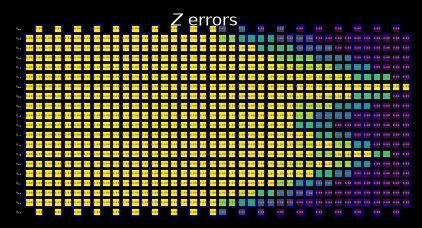

In [20]:
for p in "XYZ":
    display(
        draw_shaded_lightcone(
            boxed_circuit,
            forward_bounds,
            noise_model_paulis,
            pauli_filter=p,
            scale=0.15,
            fold=-1,
            idle_wires=False,
            wire_order=wire_order,
            measure_arrows=False,
        )
    )

#### b. 量子速度限界を使って順方向の上限を厳しくする

次に、`tighten_with_speed_limit` 関数を使って上限を厳しくします。観測量のライトコーンの幾何学的な広がりは、上で計算した順方向の上限ですでに完全に考慮されています。この関数が追加するのは、情報が回路内を伝わる速さが限られている（ライトコーンは 2 量子ビット・ゲートの層ごとに最大 1 量子ビットずつしか広がらない）ことを活用して、先に計算した上限を互いに照らし合わせて厳しくする、自己無撞着化のパスです。情報は双方向に流れます。

1. 交換子の上限から、逆伝播した観測量の上限へ: 観測量がある量子ビット上の $Z$ エラーと交換するなら、その量子ビット上で $X$ や $Y$ の成分を多く持つことはできません。
2. 逆伝播した観測量の上限から、交換子の上限へ: 観測量がある量子ビット上で $X$ と $Y$ の成分をほとんど持たないなら、その量子ビット上で $Z$ とほぼ交換するはずです。

In [21]:
forward_bounds_tighter = tighten_with_speed_limit(
    forward_bounds, boxed_circuit, noise_model_paulis, isa_observable
)

#### 目視確認のために SLC を可視化する

原理的には、この厳密化によって、計算された上限と、タイムアウト以降の層に割り当てられた自明な上限との間の移り変わりがより滑らかになります。この例では、タイムアウトに達する時点でライトコーンがすでに回路の端まで広がっているため、効果はほとんど見えません。

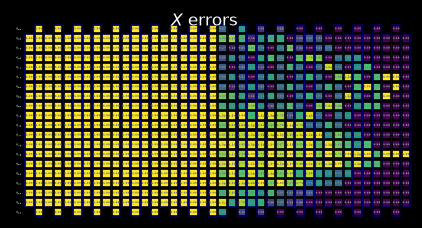

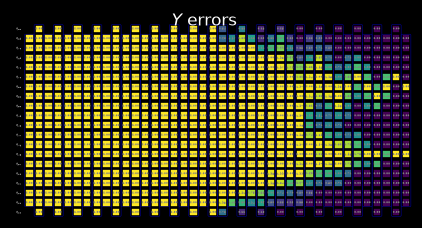

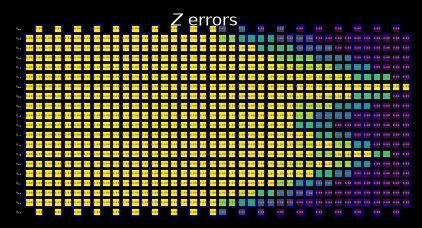

In [22]:
for p in "XYZ":
    display(
        draw_shaded_lightcone(
            boxed_circuit,
            forward_bounds_tighter,
            noise_model_paulis,
            pauli_filter=p,
            scale=0.15,
            fold=-1,
            idle_wires=False,
            wire_order=wire_order,
            measure_arrows=False,
        )
    )

#### c. 逆方向の上限を計算する

ノイズ予測のこの部分では、特定の層でのエラーが入力状態 $\rho$ にどのように影響しうるかを評価します。`compute_backward_bounds` 関数は、まず回路を反転して測定ゲートを取り除き、その後、順方向の上限の計算と同様の解析を行います。

In [23]:
backward_bounds = compute_backward_bounds(
    boxed_circuit,
    noise_model_paulis,
    evolution_max_terms=slc_evolution_max_terms,
    num_processes=slc_num_processes,
    timeout=slc_timeout,
)

#### 目視確認のために SLC を可視化する

逆方向の上限を計算すると、初期状態の構造がエラー伝播の初期の振る舞いをどのように支配しているかが分かります。

* Z エラーが最初は |0⟩ の初期状態と交換していることがはっきりと分かります。
* X 基底の +1 固有状態で初期化した量子ビット 6 でのみ、Z エラーは交換せず、X エラーは交換します。

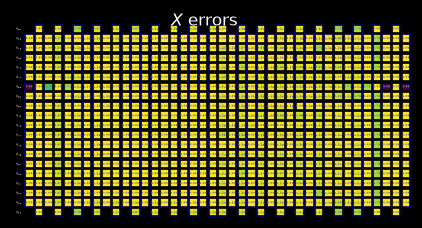

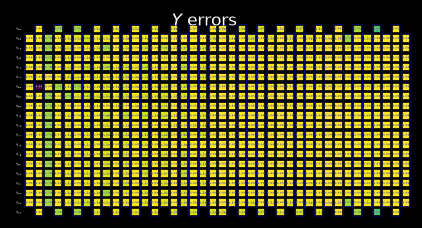

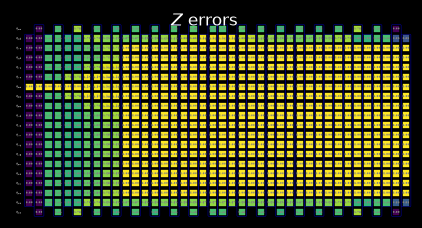

In [24]:
for p in "XYZ":
    display(
        draw_shaded_lightcone(
            boxed_circuit,
            backward_bounds,
            noise_model_paulis,
            pauli_filter=p,
            scale=0.15,
            fold=-1,
            idle_wires=False,
            wire_order=wire_order,
            measure_arrows=False,
        )
    )

#### 学習したノイズ・レートを使わずに統合した上限をプレビューする

`merged_bounds` 関数は、目的の観測量に対する推定バイアスの合計が最小になるように、回路内で逆方向の上限から順方向の上限に切り替える位置を決定します。このバイアスは、その位置より前のすべてのノイズ位置における逆方向の上限の寄与と、その位置より後のすべてのノイズ位置における順方向の上限の寄与の和として計算されます。現時点では、これはすべての量子ビットに対して一様に行われます。

<Admonition type="note" title="重要な注意">
  逆方向の上限から順方向の上限に切り替える最適な位置は、学習したノイズ・レートに依存します。この段階ではまだレートを学習していません。`noise_model_rates` はすべての層で `None` に初期化されており、`merge_bounds` はこれを一様なノイズ・レートとして扱います。したがって、ここに示す統合した上限はプレビューにすぎません。ステップ 3 で、実際に学習したレートを使って再計算します。
</Admonition>

In [25]:
merged_bounds = merge_bounds(
    boxed_circuit,
    forward_bounds_tighter,
    backward_bounds,
    noise_model_rates,
)

Missing noise rates. Partitioning backward/forward commutator bounds by assuming uniform error rates.
Optimal spacetime partitioning not implemented!Just partitioning list of noisy boxes.


### 目視確認のために SLC を可視化する

逆方向の上限と厳しくした順方向の上限を統合すると、組み合わせた SLC の振る舞いが明確になります。

* 上の関数から、逆方向の上限から厳しくした順方向の上限への切り替えが行われる区切りが選ばれていることが分かります。
* 以下を見ると、SLC が一部は逆方向の上限、一部は厳しくした順方向の上限で構成されていることが分かります。

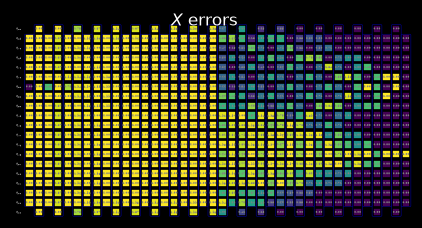

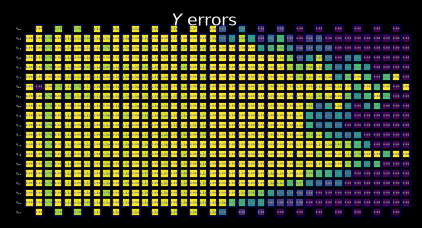

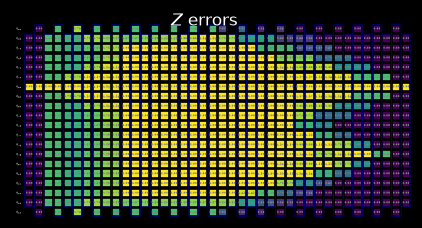

In [26]:
for p in "XYZ":
    display(
        draw_shaded_lightcone(
            boxed_circuit,
            merged_bounds,
            noise_model_paulis,
            pauli_filter=p,
            scale=0.15,
            fold=-1,
            idle_wires=False,
            wire_order=wire_order,
            measure_arrows=False,
        )
    )

### ステップ 3: 実行する

このセクションから、実際の量子デバイスを使うワークフローの部分に入ります。この学習ベースのエラー緩和手法には、2 つのステップがあります。

1. `NoiseLearnerV3` を使ってノイズを学習する。
2. `samplomatic` と `Executor` のフレームワークを使って、エラー緩和回路を実行する。

量子回路のエラーの上限が得られたので、関連するノイズ・レートを学習してエラーの予算の優先順位を決め、サンプリング・オーバーヘッドを決定し、QPU で実行します。

### a. ノイズ・レートを学習する

ノイズ・ラーナーは、スパースな [パウリ・リンドブラッド・ノイズモデル](https://arxiv.org/abs/2201.09866) に基づいて、対象となる 1 つ以上の回路のゲートに影響するノイズ過程を特性評価します。`run()` メソッドは、ノイズ・ラーナーの設定で指定したオプションを使って、与えられた固有の 2 量子ビット層に対するノイズ学習のジョブを開始します。これらのオプションでは、パウリ・ツワーリングの戦略、ランダム化の数とショット数、学習の深さ、ポストセレクションを制御します。

学習の深さも意図的に選びます。`samplomatic` を使った学習ベースの緩和における実践的な知見として、最も深い学習の深さを、緩和したい回路の深さに合わせることが非常に有益です。NLv3 の `layer_pair_depths` は層の *ペア*（層とその逆）の単位で数えるため、最も深い値を回路の 2 量子ビット層の深さの半分に設定します。

In [27]:
post_selection_enabled = True

In [28]:
# 最も深いノイズ学習の深さを、緩和する回路の深さに合わせる。
# NLv3 の ``layer_pair_depths`` は層のペア（層とその逆）の単位で数えるため、
# 最も深い値は回路の 2 量子ビット層の深さの半分になる。
# この深さまで学習すると、緩和の品質が大きく向上する。
#
# 2 量子ビット層の深さは、ボックス化する前の ISA 回路で測定する。ボックス化すると、
# すべての 2 量子ビット・ゲートが全幅の ``BoxOp`` の中に隠れるため、
# ``boxed_circuit`` に ``num_qubits == 2`` のフィルターを適用しても何も一致しない
# （また、``QuantumCircuit.depth`` はボックスの中まで再帰的に調べない）。
depth_2q = isa_circuit.depth(lambda instr: instr.operation.num_qubits == 2)
max_layer_pair_depth = depth_2q // 2  # ペアの数が必要なので 2 で割る

# 学習の深さは固定のスケジュールを使うが、回路の深さを超えるものは除外し、
# 最も深い値は常に ``max_layer_pair_depth`` を上限とする。
# これにより、緩和する回路より深く学習することはない。
candidate_depths = [1, 2, 4, 8, 12, 16, 24, 32, 40, 48]
layer_pair_depths = sorted(
    {d for d in candidate_depths if d < max_layer_pair_depth}
    | {max_layer_pair_depth}
)

noise_learner_options = {
    "num_randomizations": 64,
    "shots_per_randomization": 128,
    "layer_pair_depths": layer_pair_depths,
    "post_selection": {
        "enable": post_selection_enabled,
        "strategy": "edge",
        "x_pulse_type": "rx",
    },
    "environment": {"job_tags": ["TUT_SLC"]},
}

noise_learner = NoiseLearnerV3(backend, noise_learner_options)

In [29]:
noise_learner_job = noise_learner.run(unique_2q_instructions)

In [30]:
noise_learner_result = noise_learner_job.result()

In [31]:
if post_selection_enabled:
    print(
        "ノイズ学習実験で保持されたショットの割合の最小値: ",
        end="",
    )
    print(
        f"{min([min(d.values()) for d in [nlr.metadata['post_selection']['fraction_kept'] for nlr in noise_learner_result[:2]]]):.2f}"
    )

ノイズ学習実験で保持されたショットの割合の最小値: 0.61


In [32]:
# 各 InjectNoise.ref を学習済みの PauliLindbladMap に対応付ける辞書を取得する
refs_2_plm = noise_learner_result.to_dict(
    unique_2q_instructions, require_refs=False
)

### b.i. 実際に学習したノイズ・レートで統合した上限を更新する

具体的なノイズモデルを学習できたので、学習したノイズ・レートを予測したノイズ上限に適用し、バイアスを最小化するうえでどの上限が最も影響が大きいかを最終的に決定できます。

In [33]:
merged_bounds = merge_bounds(
    boxed_circuit,
    forward_bounds_tighter,
    backward_bounds,
    refs_2_plm,
)

Optimal spacetime partitioning not implemented!Just partitioning list of noisy boxes.


#### b.ii. ハードウェア実行のための `local_scales` を計算する

`compute_local_scales` は、回路内で考えられる各ノイズ・エラーを調べ、そのエラーが最終的な測定にどの程度のバイアスを与えうるか、また、それを補正するのにどの程度のコストがかかるかを推定します。そして、緩和する価値の高い順にエラーをランク付けし、許容されたサンプリング・コストの予算内に収まる（または目的の精度を達成する）範囲で、バイアスをできるだけ減らすサブセットを選びます。その結果として、どのエラーを積極的に緩和し、どのエラーを緩和せずに残すかを示すスケーリング係数の集合（`local_scales`）と、予測されるサンプリング・コストのオーバーヘッドの合計（`sampling_costs`）、および残りのバイアス（`residual_bias_bound`）が得られます。

残りのバイアスを目的の値に制御できることは、PEC の SLC 実装の重要な特徴です。[元の実装](https://arxiv.org/abs/2201.09866) ではサンプリング・オーバーヘッドが常にバイアスゼロを目標としていたのに対し、SLC では、予想される残りのバイアスとのトレードオフで、必要なサンプリング・オーバーヘッドを調整できます。これにより、固定のサンプリング予算の範囲内に収めやすくなります。これは特に、ワークフローの初期のプロトタイピングの段階で役立ちます。

In [34]:
id_map = map_modifier_ref_to_ref(boxed_circuit)

In [35]:
summed_rates = 0.0
for box_id, noise_id in id_map.items():
    learned_plm = refs_2_plm[noise_id]
    summed_rates += np.sum(learned_plm.rates)
    # print(f"{box_id}:\tgamma = {np.exp(2 * summed_rates):1.6e}\tsampling cost = {np.exp(4 * summed_rates):1.6e}")
total_gamma = np.exp(2 * summed_rates)
print(
    f"完全な PEC の gamma={total_gamma}、サンプリング・コスト (gamma^2) = {total_gamma**2}"
)

完全な PEC の gamma=35.23359391269886、サンプリング・コスト (gamma^2) = 1241.40614000497


In [36]:
biases = []
costs = []
for bias in [0.0] + np.arange(0.001, 0.102, 0.01).tolist():
    _, cost_, bias_ = compute_local_scales(
        boxed_circuit,
        merged_bounds,
        refs_2_plm,
        sampling_cost_budget=np.inf,
        bias_tolerance=bias,
    )
    biases.append(bias_)
    costs.append(cost_)

#### サンプリング・オーバーヘッドと残留バイアスのトレードオフ

Text(0.5, 0.98, 'PEC sampling overhead reduction due to SLC')

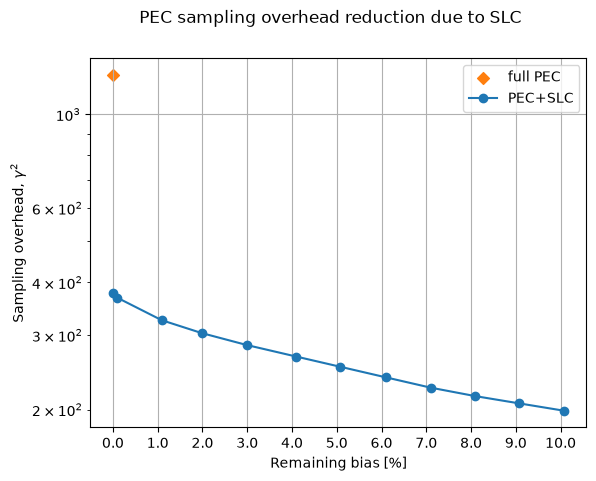

In [37]:
xticks = np.arange(0, 11)

fig, ax = plt.subplots()
ax.scatter(
    [0], [total_gamma**2], marker="D", c="tab:orange", label="full PEC"
)
ax.plot(
    100 * np.array(biases),
    np.array(costs),
    "o-",
    c="tab:blue",
    label="PEC+SLC",
)
ax.set_yscale("log")
ax.set_xticks(xticks, [f"{x:.1f}" for x in xticks])

ax.set_xlabel("Remaining bias [%]")
ax.set_ylabel(r"Sampling overhead, $\gamma^2$")
ax.grid()
ax.legend()
fig.suptitle("PEC sampling overhead reduction due to SLC")

In [38]:
chosen_bias_thres = 0.1

In [39]:
local_scales, sampling_cost, residual_bias_bound = compute_local_scales(
    boxed_circuit,
    merged_bounds,
    refs_2_plm,
    sampling_cost_budget=np.inf,
    bias_tolerance=chosen_bias_thres,
)
print(
    f"PEC+SLC のサンプリング・コスト (gamma^2) = {sampling_cost}、"
    f"残りのバイアス = {100 * residual_bias_bound:.1f}%"
)

PEC+SLC のサンプリング・コスト (gamma^2) = 199.48120073799495、残りのバイアス = 10.0%


### c. アンチノイズを加えて対象の回路を実行する

#### c.i. `samplex` を使ってテンプレート回路を準備する

`samplex` は Samplomatic の `build` メソッドの出力であり、`template_circuit` のランダム化されたパラメーターを生成するのに必要なすべての情報をエンコードしています。これらは `QuantumProgram` オブジェクトの設定に使われ、そのオブジェクトが `Executor` プリミティブによって QPU 上で実行されます。各 `QuantumProgram` には複数のアイテムを含めることができ、それぞれのアイテムは `template` と `samplex` のペアと考えることができます。

詳しくは、[Hello samplomatic](https://github.com/qiskit-community/qdc-challenges-2025/blob/main/day3_tutorials/Track_A/hello_samplomatic/Samplomatic%20-%20Hello%20World.ipynb) のチュートリアルを参照してください。

In [40]:
# 後で "Executor" で使うために、テンプレート回路と samplex をビルドする
template_circuit, samplex = samplomatic.build(boxed_circuit)

In [41]:
# ポストセレクションが有効な場合は設定する
if post_selection_enabled:
    # ポストセレクション用の PM を設定する（PS の命令を追加するため）
    post_selection_pm = PassManager(
        [
            AddSpectatorMeasures(backend.coupling_map),
            AddPostSelectionMeasures(x_pulse_type="rx"),
        ]
    )
    final_template_circuit = post_selection_pm.run(template_circuit)
else:
    final_template_circuit = template_circuit

#### c.ii. `QuantumProgram` を設定する

In [42]:
num_randomizations = 4096
shots_per_randomization = 64
chunk_size = 256

In [43]:
# QuantumProgram を設定する
program = QuantumProgram(shots=shots_per_randomization, noise_maps=refs_2_plm)

# エラー緩和なし

# samplex_inputs にバインドする必要があるその他の引数を辞書にまとめる
samplex_inputs = {
    f"noise_scales.{ref}": float(0) for ref in local_scales.keys()
}
samplex_inputs |= {"basis_changes": {"basis0": bases_canon[0]}}

# QuantumProgram に渡すために samplex_inputs を辞書に変換する
samplex_arguments = (
    samplex.inputs().bind(**samplex_inputs).make_broadcastable()
)

program.append_samplex_item(
    circuit=final_template_circuit,
    samplex=samplex,
    samplex_arguments=samplex_arguments,
    shape=(num_randomizations,),
    chunk_size=chunk_size,
)

# 通常の PEC

# samplex_inputs にバインドする必要があるその他の引数を辞書にまとめる
samplex_inputs = {
    f"noise_scales.{ref}": float(-1) for ref in local_scales.keys()
}
samplex_inputs |= {"basis_changes": {"basis0": bases_canon[0]}}

# QuantumProgram に渡すために samplex_inputs を辞書に変換する
samplex_arguments = (
    samplex.inputs().bind(**samplex_inputs).make_broadcastable()
)

program.append_samplex_item(
    circuit=final_template_circuit,
    samplex=samplex,
    samplex_arguments=samplex_arguments,
    shape=(num_randomizations,),
    chunk_size=chunk_size,
)

# PEC+SLC

# samplex_inputs にバインドする必要があるその他の引数を辞書にまとめる
samplex_inputs = {
    f"noise_scales.{ref}": float(-1) for ref in local_scales.keys()
}
samplex_inputs |= {"basis_changes": {"basis0": bases_canon[0]}}
samplex_inputs |= {"local_scales": local_scales}

# QuantumProgram に渡すために samplex_inputs を辞書に変換する
samplex_arguments = (
    samplex.inputs().bind(**samplex_inputs).make_broadcastable()
)

program.append_samplex_item(
    circuit=final_template_circuit,
    samplex=samplex,
    samplex_arguments=samplex_arguments,
    shape=(num_randomizations,),
    chunk_size=chunk_size,
)

#### c.iii. `Executor` プリミティブでプログラムを実行する

In [44]:
executor = Executor(backend)

In [45]:
job_exec = executor.run(program)

In [46]:
results_exec = job_exec.result()

### ステップ 4: 後処理を行う

`executor_expectation_values` を使って最終的な目的の期待値を計算する際に、できるだけ高品質な結果が得られるよう、いくつかの後処理の手法を実装します。まず、読み出しの過程で生じるエラーに対処する [Twirled Readout Error eXtinction（TREX）](/docs/guides/error-mitigation-and-suppression-techniques#twirled-readout-error-extinction-trex) を適用します。次に、ポストセレクションの手法を使って、Heron バックエンドの非マルコフ的ノイズによるエラーを修正します。この手法では、アクティブな量子ビットとスペクテーター量子ビットを測定し、各量子ビットにゆっくりとした回転を適用してから、再度測定します。2 回の測定で、量子ビットが期待どおりに反転したことが確認できなかった場合、`PostSelector` の `mask` を適用してそのショットを破棄します。マスクの計算では、1 量子ビットのノード単位、または隣接するスペクテーターのエッジ単位でフィルタリングする特定の戦略を設定できます。これは、除外されるショットの数と結果の品質の両方に影響します。

In [47]:
measurement_noise_map = noise_learner_result[2].to_pauli_lindblad_map()
trex_scale_factors = trex_factors(measurement_noise_map, reverser_virt)

In [48]:
post_selection_strategy = "node"

In [49]:
def post_process_conv(datum, steps=16, gamma=None, ps=False, trex=False):
    meas = datum["meas"]
    flips = datum["measurement_flips.meas"]
    signs = datum.get("pauli_signs", None)

    meas_basis_axis = None
    avg_axis = 0

    mask = None
    if ps and post_selection_enabled:
        # 結果をポストセレクションする
        post_selector = PostSelector.from_circuit(
            circuit=final_template_circuit, coupling_map=backend.coupling_map
        )

        # 結果をフィルタリングするための PS マスクを計算する
        mask = post_selector.compute_mask(
            datum, strategy=post_selection_strategy
        )

        # ポストセレクションで保持されたショットの割合を計算する
        total_num_shots = num_randomizations * shots_per_randomization
        ps_ratio = np.sum(mask) * 100 / total_num_shots / len(bases_canon)
        print(
            f"{post_selection_strategy} ベースのポストセレクションを適用（ショットの {ps_ratio:.1f}% を保持）:"
        )

    results = []
    for i in range(steps, num_randomizations + 1, steps):
        # ポストセレクションの有無に応じて、緩和した期待値を計算する
        res = executor_expectation_values(
            meas[:i],
            reverser_virt,
            meas_basis_axis,
            avg_axis=avg_axis,
            measurement_flips=flips[:i],
            pauli_signs=signs[:i] if signs is not None else None,
            postselect_mask=mask[:i] if mask is not None else None,
            rescale_factors=trex_scale_factors if trex else None,
            gamma_factor=gamma,
        )
        results.append(res[0])
    return results

In [50]:
gamma_pec = gamma_from_noisy_boxes(refs_2_plm, id_map)
gamma_slc = gamma_from_noisy_boxes(refs_2_plm, id_map, local_scales)

In [51]:
steps = 16

In [ ]:
results = {}

for label, result_idx, gamma, use_ps, use_trex in [
    ("PEC", 1, gamma_pec, True, True),
    ("PEC+SLC", 2, gamma_slc, True, True),
    ("Unmitigated", 0, None, False, False),
]:
    res = post_process_conv(
        results_exec[result_idx],
        steps=steps,
        gamma=gamma,
        ps=use_ps,
        trex=use_trex,
    )
    results[label] = res

実験結果を調べると、PEC、PEC と SLC の組み合わせ、緩和なしのベースラインという異なる手法の振る舞いを直接比較できます。特に注目すべき点は次のとおりです。

* 緩和なしの結果は 10% のバイアス帯から大きく外れており（0.35 付近）、ランダム化の数の影響を受けません。
* このデバイスでは、完全な PEC のサンプリング・オーバーヘッドは $\gamma^2 \approx 1.6\times10^2$ です。初期の大きな揺れの後、通常の PEC の推定値は信号を回復し、1.1 付近に落ち着いて、厳密な値をわずかに上回ります。10% のバイアス帯は PEC+SLC の推定量にのみ適用されることに注意してください。通常の PEC は原理的にバイアスがないため、この残留偏差はバイアスの保証の対象外であり、統計的な揺らぎと学習したノイズモデルの不完全性を反映しています。この問題の規模では妥当なものです。
* SLC によってオーバーヘッドはさらに約 3.4 分の 1 に削減されます（残留バイアスの上限が約 10% で、$\gamma^2 \approx 48$）。PEC+SLC もランダム化の数が少ないうちは大きく揺らぎ、最初は非物理的な領域に入ることさえありますが、推定値は着実に厳密な値へ収束し、帯の内側に十分収まる 1.0 付近に落ち着きます。サンプリング・コストが約 3 分の 1 であるにもかかわらず、通常の PEC と同等以上の精度が得られており、ライトコーン・シェーディングの利点を示しています。
* ランダム化が蓄積するにつれて、緩和した両方の推定値の誤差棒は小さくなります。ランダム化の数が同じ場合、PEC+SLC の推定量のほうが統計的な分散が小さく、これは $\gamma^2$ が小さいことと整合しています。

学習したノイズ・レート（したがって、オーバーヘッドと緩和した推定値）は、バックエンドとその実行時点でのキャリブレーションに依存するため、このノートブックを再実行すると、定量的に異なる値が得られることがあります。

(-50.0, 4100.0)

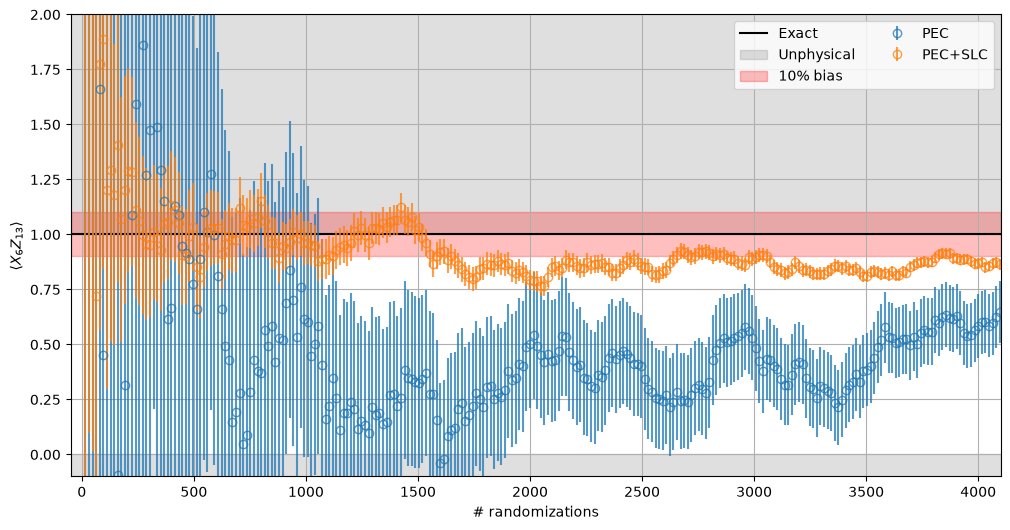

In [53]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.axhline(1.0, color="black", label="Exact")
ax.fill_between(
    [-50, 4100], -10, 0, color="grey", alpha=0.25, label="Unphysical"
)
ax.fill_between([-50, 4100], 1, 10, color="grey", alpha=0.25)
ax.fill_between(
    [-50, 4100], 0.9, 1.1, color="red", alpha=0.25, label="10% bias"
)

for label, res in results.items():
    ax.errorbar(
        list(range(steps, num_randomizations + 1, steps)),
        [r[0] for r in res],
        yerr=[r[1] for r in res],
        alpha=0.75,
        marker="o",
        linestyle="",
        markerfacecolor="none",
        label=label,
    )

ax.set_ylabel(r"$\langle X_{6}Z_{13}\rangle$")
ax.set_xlabel("# randomizations")
ax.grid()

ax.legend(ncols=2)
ax.set_ylim([-0.1, 2.0])
ax.set_xlim([-50, 4100])

## 次のステップ

この内容に興味を持たれた方には、次の資料もお勧めします。

**おすすめ**
  * [Estimator プリミティブでのエラー緩和オプションの組み合わせ](/docs/tutorials/combine-error-mitigation-techniques)
  * [確率的エラー増幅によるユーティリティー・スケールのエラー緩和](/docs/tutorials/probabilistic-error-amplification)
  * [`qiskit-addon-slc`](https://github.com/Qiskit/qiskit-addon-slc) と [`samplomatic`](https://github.com/Qiskit/samplomatic) のドキュメント
  * [Lightcone shading for classically accelerated quantum error mitigation](https://arxiv.org/abs/2409.04401)


© IBM Corp., 2017-2026